In [66]:
import sys
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from hcipy import * 
sys.path.append(os.path.abspath(os.path.join(os.path.dirname('adc_sims'), '..')))
from slicing_class import adcFitter2

In [67]:
wavelength = 764E-9
bw = 126E-9
wavelength_normalized = wavelength / 656E-9
bw_normalized = bw / wavelength
grating_angle = 28
grating_freq = 47

ADC = adcFitter2(wavelength=wavelength,bandwidth=bw,grating_angle=grating_angle,grating_freq=grating_freq,snr_threshold=2.6,speckle_window=60)

In [68]:
#import sweep datacube
#cube = read_field('/Users/Katie/Documents/MagAO-X/simulations/adc_sims/lab_analysis/fields/unsats/comparison_sweep.fits')
#cube = read_field('/Users/Katie/Documents/MagAO-X/Data/ADC/nov11th_onsky/onsky_counterrotation.fits')
cube = read_field('/Users/Katie/Documents/MagAO-X/Data/ADC/nov9th/counterrotation.fits')

In [69]:
print(len(cube))

51


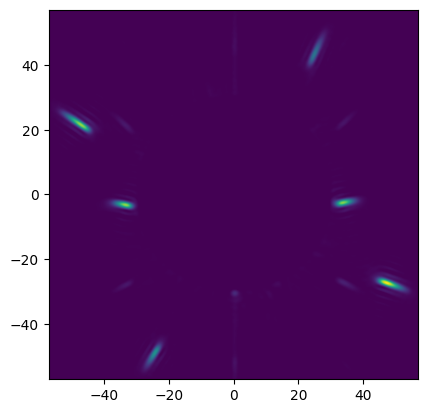

In [70]:
img = ADC.filter_image(ADC.crop_image(cube[13]))
imshow_field(img)

In [ ]:
#dispersion vector estimator
def est_mag_dir(psf,plotted=False):
    slopes = np.zeros(4)
    intercepts = np.zeros(4)
    points = []
    lines = np.zeros((4,3))

    for i in range(4):
        #print(ADC.slice_speckle_angle(psf,i,positions=True))
        try:
            angle,point = ADC.slice_speckle_angle(psf,i,positions=True)
        except:
            print(f'fitting not successful for speckle {i}')
            return np.nan
        if i == 0 or i ==2:
            angle = 90 - angle

        slope = np.tan(np.radians(angle))
        slopes[i] = slope
        points.append(point)
        intercepts[i] = -slope * point[0] + point[1]

    for j in range(4):
        lines[j,0] = slopes[j]
        lines[j,1] = -1
        lines[j,2] = points[j][1] - slopes[j]*points[j][0]

    A = lines[:,0]
    B = lines[:,1]
    C = lines[:,2]
    norm = np.sqrt(A**2 + B**2)

    A /= norm
    B /= norm
    C /= norm

    M = np.stack((A.T,B.T),axis=1)
    C = -C

    (x, y), *_ = np.linalg.lstsq(M, C)
    print(f'least-squares solution: ({x},{y})')
    magnitude_guess = np.sqrt(x**2+y**2) / 100

    #added logic for quadrants
    if x > 0 and y > 0: #i
        orientation_guess = np.degrees(np.atan(y/x))
    elif x < 0 and y >0: #ii
        orientation_guess = 180+np.degrees(np.atan(y/x))
    elif x < 0 and y < 0: #iii
        orientation_guess = -np.degrees(np.atan(y/x))
    else: #iv
        orientation_guess = -180-np.degrees(np.atan(y/x))

    print(f'Estimated dispersion direction {orientation_guess}°')
    print(f'Estimated dispersion magnitude {magnitude_guess}')

    if plotted:
        imshow_field(psf)
        a = np.array(psf.grid.x)

        for i in range(4):
            plt.plot(a, slopes[i] * a + intercepts[i],'w--',linewidth=0.5)

        plt.plot(x,y,'o',color='orange',label='dispersed speckle center')
        plt.plot(0,0,'o',color='red',label='psf center')

        plt.xlim((-60,60))
        plt.ylim((-60,60))
        plt.legend(loc='upper right')
        
    return magnitude_guess,orientation_guess


[-24.14285714 -48.42857143]


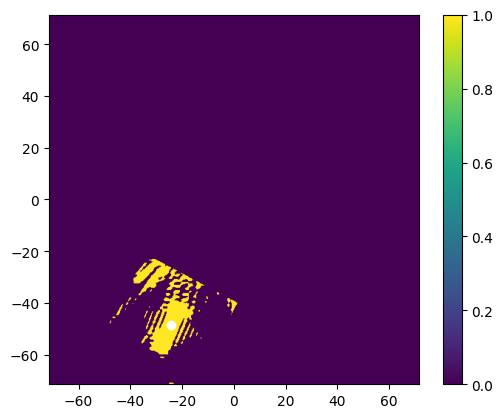

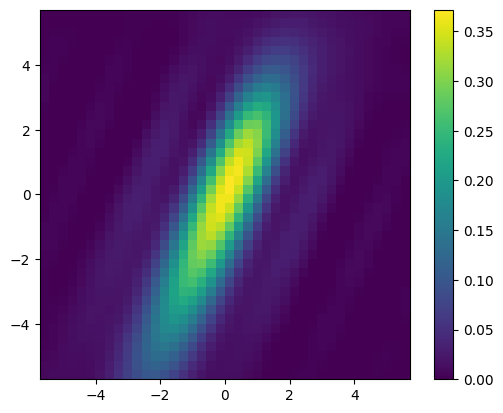

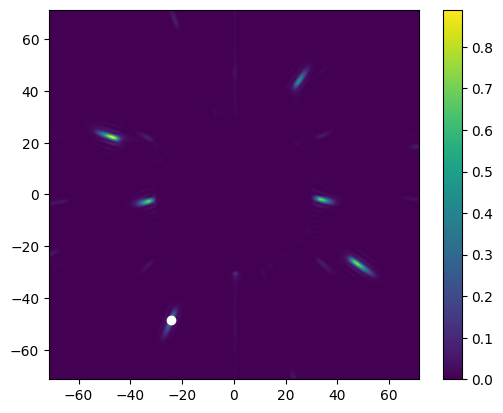

In [72]:
extent=40
speckle_number = 2
img = ADC.filter_image(ADC.crop_image(cube[48],extent=500))

speckle_coords = np.array([[0, ADC.grating_freq * ADC.normalized_wavelength],[ADC.grating_freq * ADC.normalized_wavelength,0],[0, -ADC.grating_freq * ADC.normalized_wavelength],[-ADC.grating_freq * ADC.normalized_wavelength,0]])
speckle_center = speckle_coords[speckle_number]
rect = make_rotated_aperture(make_rectangular_aperture(size=(extent,extent), center=speckle_center), np.deg2rad(-ADC.grating_angle))(img.grid)

speckle_img = rect * img
plt.figure()
imshow_field(speckle_img > 0)
plt.colorbar()

#center_of_intensity = np.array([sum(speckle_img*speckle_img.grid.x)/sum(speckle_img),sum(speckle_img*speckle_img.grid.y)/sum(speckle_img)])
center_of_intensity = speckle_img.grid[np.argmax(speckle_img)] #using the argmax instead of the center of intensity!!!!
print(center_of_intensity)

#new_img = ADC.window_field(img,[center_of_intensity[0],center_of_intensity[1]],extent,extent)
new_img = ADC.window_field(img,center_of_intensity,extent,extent)
plt.plot(center_of_intensity[0],center_of_intensity[1],'o',color='white')

plt.figure()
imshow_field(new_img)
plt.colorbar()

plt.figure()
imshow_field(img)
plt.colorbar()
plt.plot(center_of_intensity[0],center_of_intensity[1],'o',color='white')

least-squares solution: (0.19739204429382085,-15.460064159840213)
Estimated dispersion direction -90.73150514938423°
Estimated dispersion magnitude 0.15461324246180416


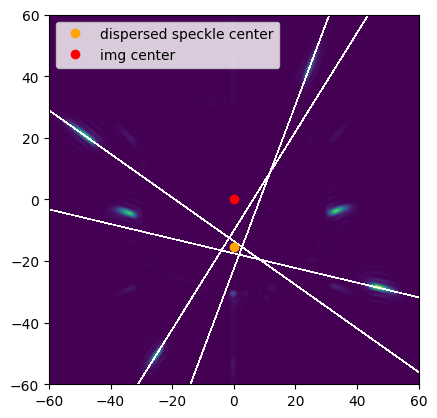

In [73]:
img = ADC.filter_image(ADC.crop_image(cube[1],extent=510))
imshow_field(img)
h = est_mag_dir(img,plotted=True)

/Users/Katie/Documents/MagAO-X/simulations/adc_sims/slicing_class.py:23: RuntimeWarning: overflow encountered in exp
  return np.exp(-(x-mu)**2 / (2 * sigma2) )
/Users/Katie/Documents/MagAO-X/simulations/adc_sims/.venv/lib/python3.13/site-packages/scipy/optimize/_minpack_py.py:497: RuntimeWarning: overflow encountered in matmul
  cov_x = invR @ invR.T
/Users/Katie/Documents/MagAO-X/simulations/adc_sims/slicing_class.py:49: OptimizeWarning: Covariance of the parameters could not be estimated
  popt = curve_fit(self.gauss,x,isolated,p0=[np.argmax(data),2])


[88.15258511 72.12111441 85.83534512 26.20844661]
least-squares solution: (44.40718280849684,21.011264632260236)
Estimated dispersion direction 25.321178343716362


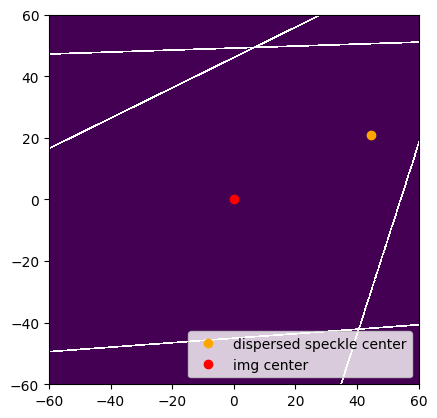

In [115]:
angs = ADC.all_speckle_angles(img)
print(angs)

#use a slope and a point on each of the speckles to do point-slope form and convert to y = mx + b form. 
angle1, point1 = ADC.slice_speckle_angle(img,0,positions=True)
angle1 = 90 - angle1
slope1 = np.tan(np.radians(angle1))
intercept1 = -slope1 * point1[0] + point1[1]

angle3, point3 = ADC.slice_speckle_angle(img,2,positions=True)
angle3 = 90 - angle3
slope3 = np.tan(np.radians(angle3))
intercept3 = -slope3 * point3[0] + point3[1]

angle2, point2 = ADC.slice_speckle_angle(img,1,positions=True)
slope2 = np.tan(np.radians(angle2))
intercept2 = -slope2 * point2[0] + point2[1]

angle4, point4 = ADC.slice_speckle_angle(img,3,positions=True)
slope4 = np.tan(np.radians(angle4))
intercept4 = -slope4 * point4[0] + point4[1]

#a,b,c coefficients
line1 = np.array([slope1, -1, point1[1]-slope1*point1[0]])
line2 = np.array([slope2, -1, point2[1]-slope2*point2[0]])
line3 = np.array([slope3, -1, point3[1]-slope3*point3[0]])
line4 = np.array([slope4, -1, point4[1]-slope4*point4[0]])

lines = np.stack((line1,line2,line3,line4))

A = lines[:,0]
B = lines[:,1]
C = lines[:,2]
norm = np.sqrt(A**2 + B**2)

A /= norm
B /= norm
C /= norm

M = np.stack((A.T,B.T),axis=1)
C = -C

(x, y), *_ = np.linalg.lstsq(M, C)
print(f'least-squares solution: ({x},{y})')
orientation_guess = np.atan(y/x)
print(f'Estimated dispersion direction {np.degrees(orientation_guess)}')

plt.figure()
imshow_field(img)
a = np.array(img.grid.x)
plt.plot(a, slope1 * a + intercept1,'w--',linewidth=0.5)
plt.plot(a, slope3 * a + intercept3,'w--',linewidth=0.5)

plt.plot(a, slope2 * a + intercept2,'w--',linewidth=0.5)
plt.plot(a, slope4 * a + intercept4,'w--',linewidth=0.5)

plt.plot(x,y,'o',color='orange',label='dispersed speckle center')
plt.plot(0,0,'o',color='red',label='img center')

plt.xlim((-60,60))
plt.ylim((-60,60))
plt.legend(loc='lower right')
plt.show()

0
least-squares solution: (0.2631536845376258,-15.994177891801257)
Estimated dispersion direction -90.94260769682657°
Estimated dispersion magnitude 0.1599634259123847


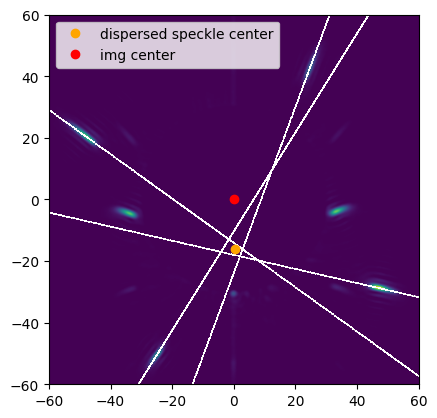

1
least-squares solution: (0.19739204429382085,-15.460064159840213)
Estimated dispersion direction -90.73150514938423°
Estimated dispersion magnitude 0.15461324246180416


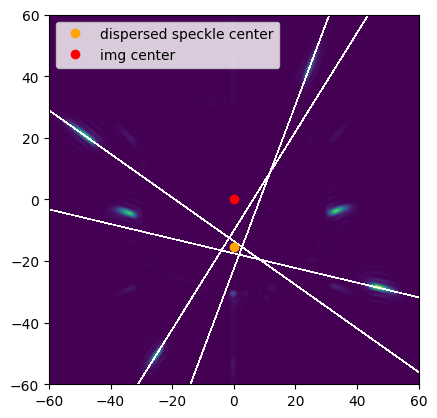

2
least-squares solution: (0.3661960923786995,-15.160758323773768)
Estimated dispersion direction -91.38366506258608°
Estimated dispersion magnitude 0.15165180266978331


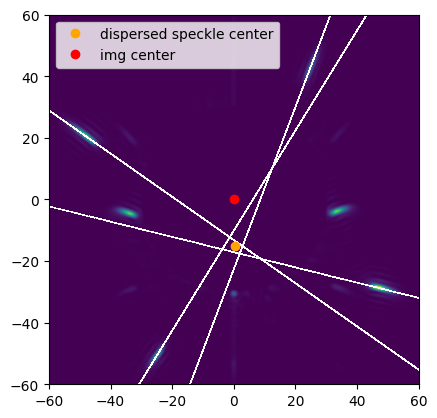

3
least-squares solution: (0.04839171814378727,-14.61441502931203)
Estimated dispersion direction -90.18971892300952°
Estimated dispersion magnitude 0.14614495147194317


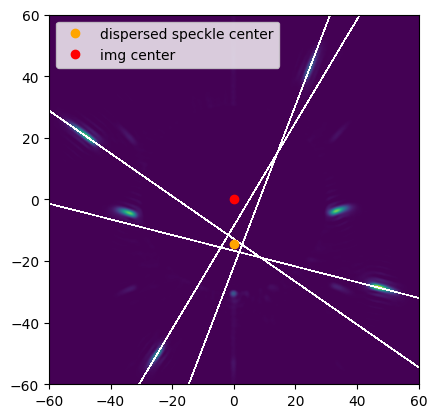

4
least-squares solution: (0.12695670031955777,-14.326314251406794)
Estimated dispersion direction -90.50772952319434°
Estimated dispersion magnitude 0.1432687677178168


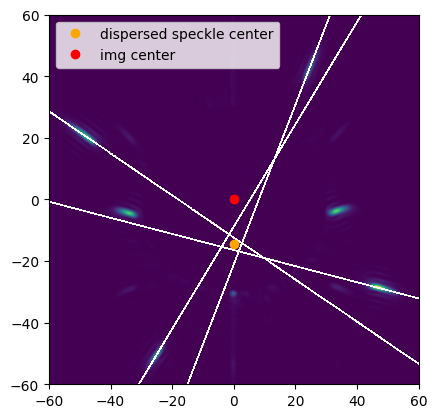

5
least-squares solution: (0.14590886379636933,-13.819648166982937)
Estimated dispersion direction -90.60491058617296°
Estimated dispersion magnitude 0.1382041840378681


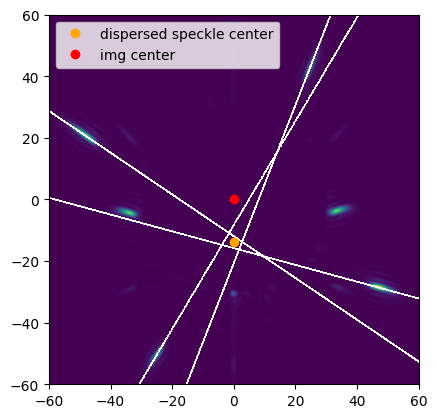

6
least-squares solution: (0.045560280567923925,-13.294525274946336)
Estimated dispersion direction -90.19635161970115°
Estimated dispersion magnitude 0.1329460334215927


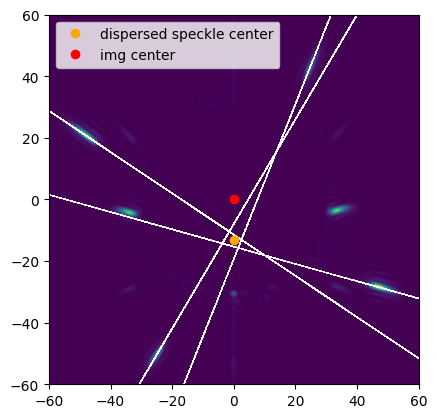

7
least-squares solution: (-0.07975515583377052,-12.875930766209628)
Estimated dispersion direction -89.64510717969634°
Estimated dispersion magnitude 0.12876177770639302


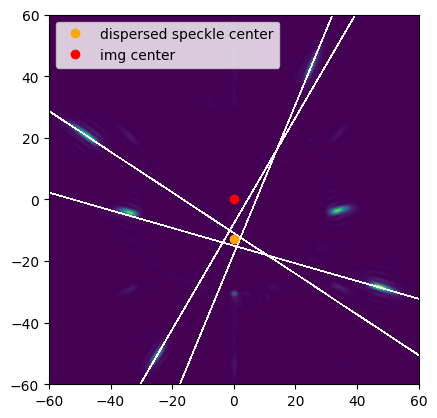

8
least-squares solution: (0.06159771037360323,-12.492465681862296)
Estimated dispersion direction -90.28251110070792°
Estimated dispersion magnitude 0.12492617543590713


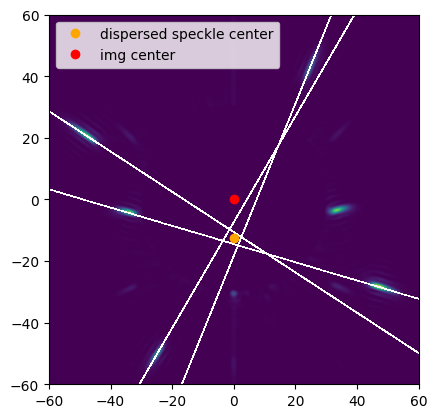

9
least-squares solution: (-0.036662486969969446,-12.065110500610926)
Estimated dispersion direction -89.8258947314054°
Estimated dispersion magnitude 0.12065166203990016


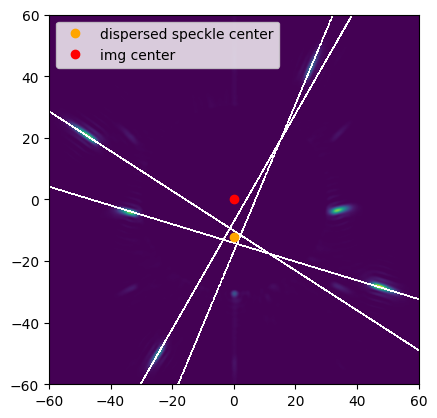

10
least-squares solution: (-0.04261765839672906,-11.528177137620258)
Estimated dispersion direction -89.7881884702052°
Estimated dispersion magnitude 0.11528255912372766


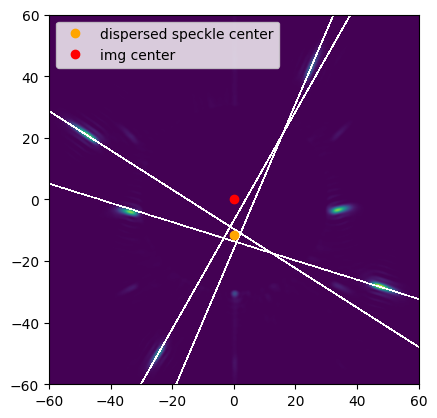

11
least-squares solution: (-0.12305046096635994,-10.689786853550855)
Estimated dispersion direction -89.34049567069428°
Estimated dispersion magnitude 0.10690495048887713


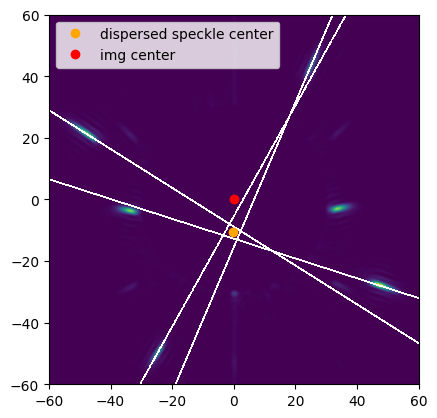

12
least-squares solution: (-0.027402061590212023,-10.342115378782179)
Estimated dispersion direction -89.84819171439813°
Estimated dispersion magnitude 0.10342151680430056


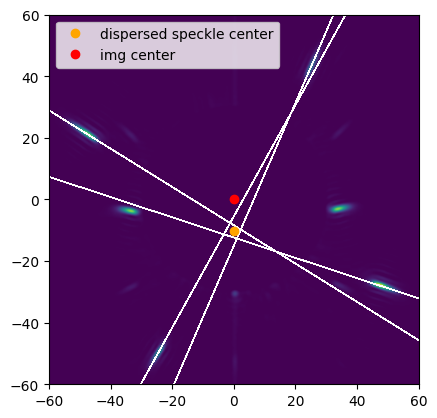

13
least-squares solution: (-0.15595397540823125,-9.418510835993558)
Estimated dispersion direction -89.05136934624201°
Estimated dispersion magnitude 0.09419801909285232


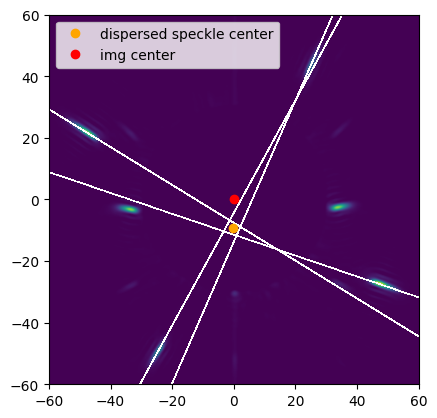

14
least-squares solution: (-0.29109383021569063,-8.932093398069473)
Estimated dispersion direction -88.133411028694°
Estimated dispersion magnitude 0.08936835462837273


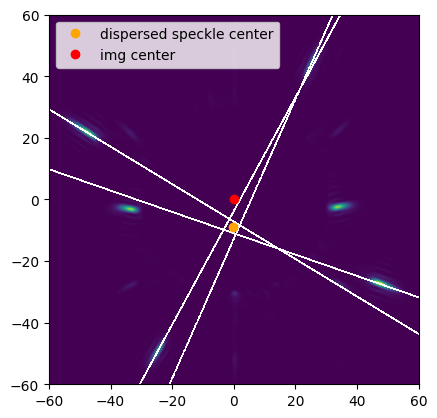

15
least-squares solution: (-0.5717781471146215,-8.35946142637918)
Estimated dispersion direction -86.08712488683577°
Estimated dispersion magnitude 0.08378993113055964


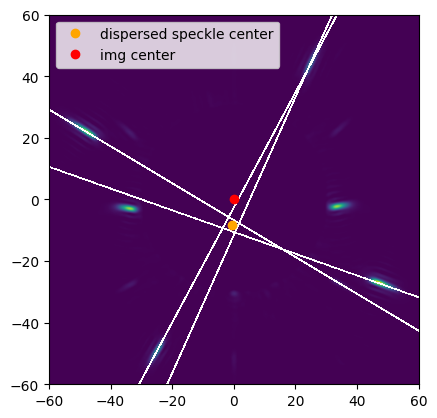

16
least-squares solution: (-0.9391889032069598,-7.944524099076061)
Estimated dispersion direction -83.25787697291453°
Estimated dispersion magnitude 0.07999846183315489


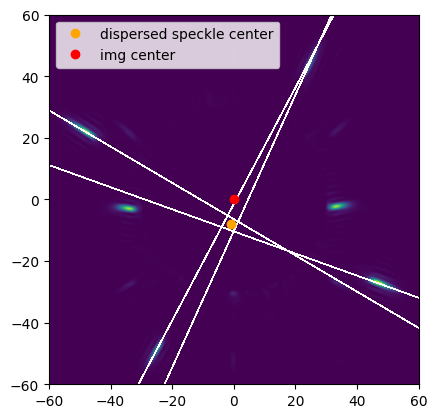

17
least-squares solution: (-0.710867188498724,-7.071959188989347)
Estimated dispersion direction -84.25995888782474°
Estimated dispersion magnitude 0.07107597268445572


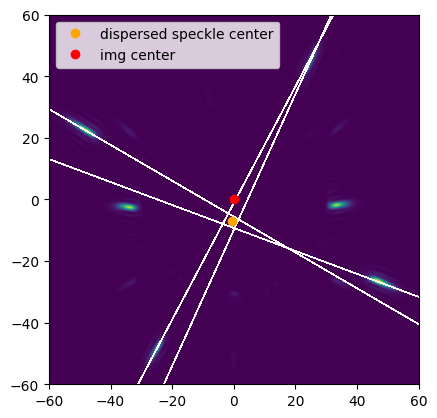

18
least-squares solution: (-0.7541860344817118,-6.16377993603503)
Estimated dispersion direction -83.02409442791546°
Estimated dispersion magnitude 0.062097487609785985


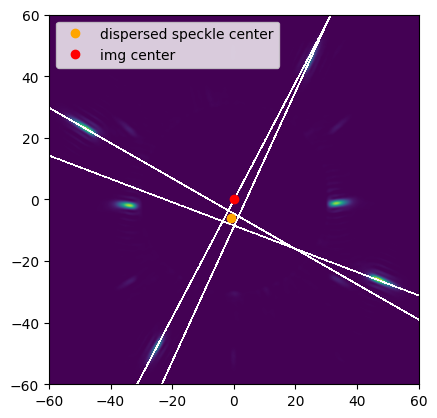

19
least-squares solution: (-0.47299154988189857,-5.841149780786868)
Estimated dispersion direction -85.37053159584949°
Estimated dispersion magnitude 0.05860268916000882


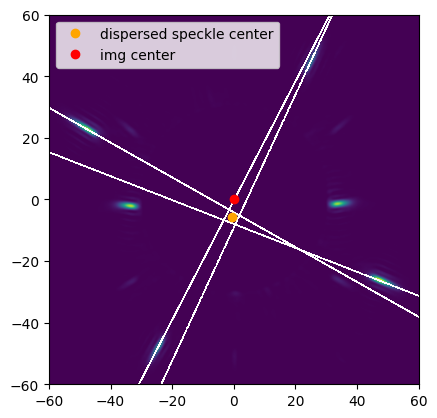

20
least-squares solution: (-0.5713781455185853,-5.219573139973204)
Estimated dispersion direction -83.75279943795081°
Estimated dispersion magnitude 0.052507539219340676


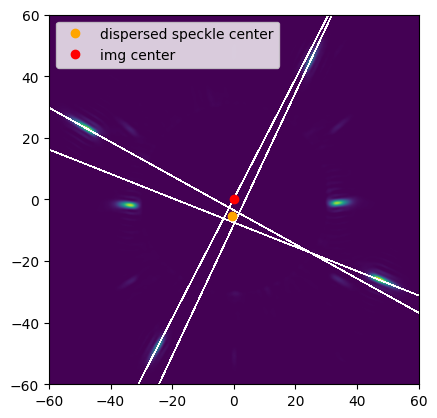

21
least-squares solution: (-0.3204635798823452,-4.018134251860697)
Estimated dispersion direction -85.44006571194285°
Estimated dispersion magnitude 0.04030893172983765


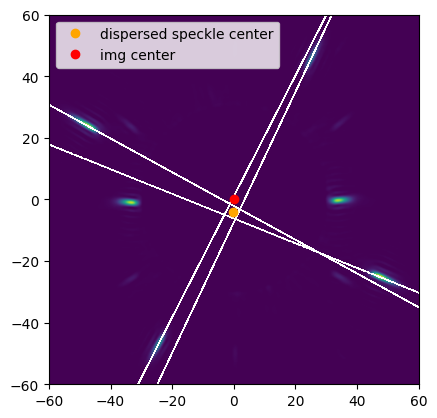

22
least-squares solution: (-0.46562923777020604,-3.804238245790155)
Estimated dispersion direction -83.02184879453941°
Estimated dispersion magnitude 0.038326282389241746


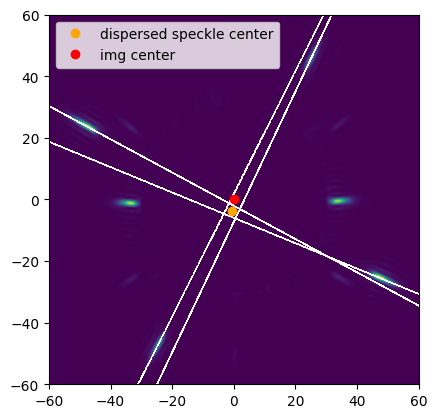

23
least-squares solution: (-0.5005139860173271,-3.1874938317484496)
Estimated dispersion direction -81.07603917444236°
Estimated dispersion magnitude 0.032265509724213826


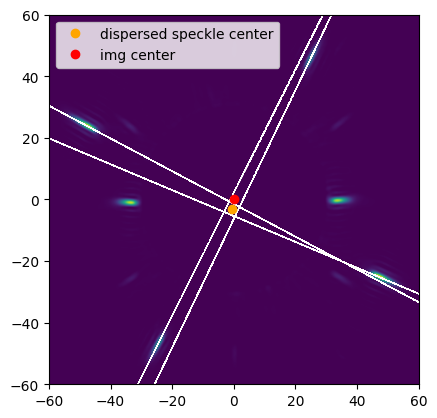

24
least-squares solution: (-0.1660375195290745,-2.87545493519528)
Estimated dispersion direction -86.6952370273046°
Estimated dispersion magnitude 0.028802447017970988


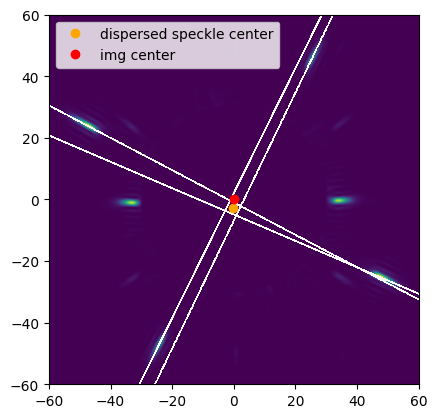

25
least-squares solution: (-0.25379684601632535,-2.489353966566054)
Estimated dispersion direction -84.17864356814043°
Estimated dispersion magnitude 0.02502258182103913


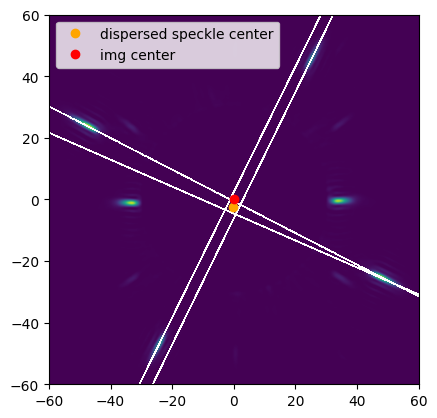

26
least-squares solution: (-0.24919066545724533,-1.8661213347621965)
Estimated dispersion direction -82.39405982515541°
Estimated dispersion magnitude 0.01882685535028531


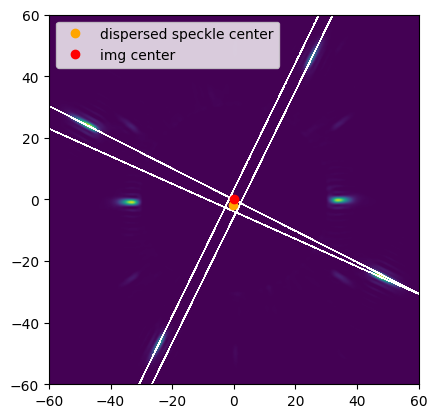

27
least-squares solution: (-0.4054221120968694,-1.2673217980991596)
Estimated dispersion direction -72.26028519295483°
Estimated dispersion magnitude 0.013305907067593601


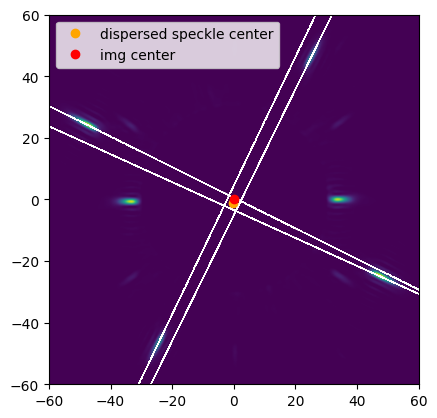

28
least-squares solution: (-0.5823677638026087,-0.7305382934373458)
Estimated dispersion direction -51.43898017015748°
Estimated dispersion magnitude 0.009342582140365695


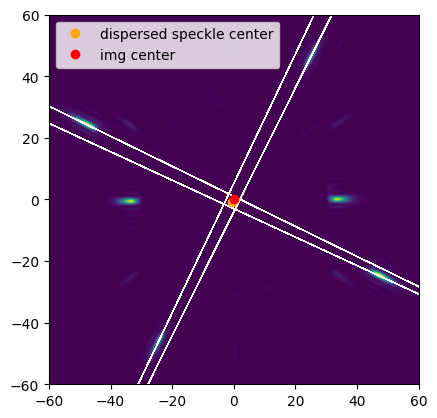

29
least-squares solution: (-0.7235629107957982,-0.09803711549140214)
Estimated dispersion direction -7.716141003019781°
Estimated dispersion magnitude 0.007301743366437653


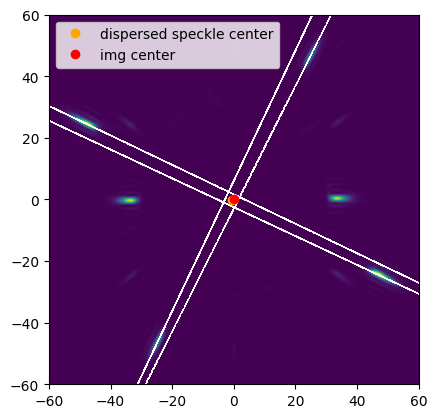

30
least-squares solution: (-0.550797383109872,0.5538002098192725)
Estimated dispersion direction 134.84424294029017°
Estimated dispersion magnitude 0.007810713345377318


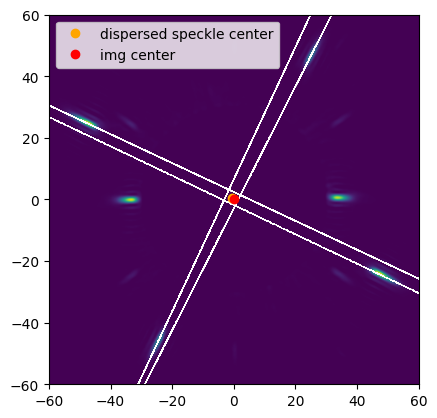

31
least-squares solution: (0.03276410966457821,1.2962237662883052)
Estimated dispersion direction 88.55206669477354°
Estimated dispersion magnitude 0.01296637782564102


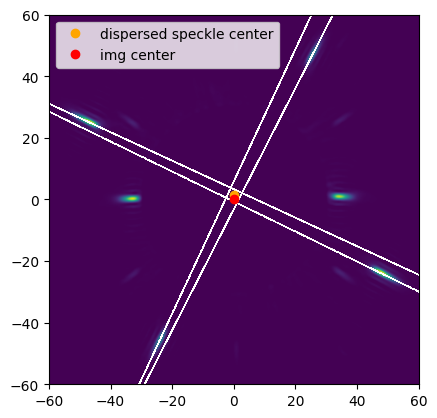

32
least-squares solution: (0.11750319009263212,1.7205581978206976)
Estimated dispersion direction 86.09312877130765°
Estimated dispersion magnitude 0.017245658908171507


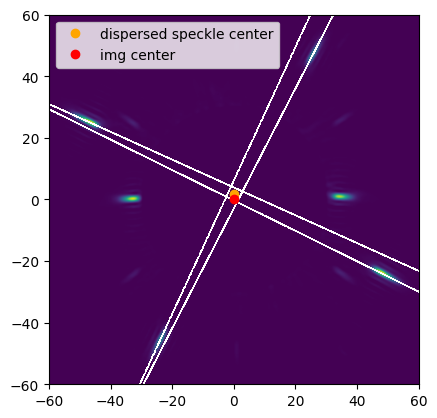

33
least-squares solution: (0.023951977673552748,2.294706044418095)
Estimated dispersion direction 89.40197246656317°
Estimated dispersion magnitude 0.02294831045528933


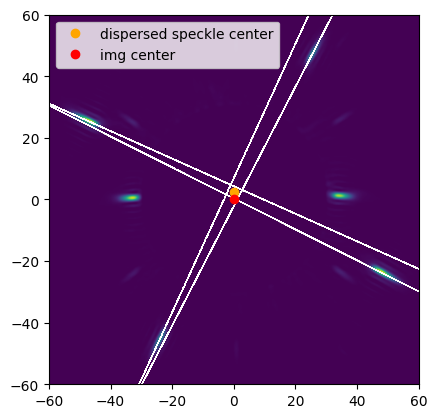

34
least-squares solution: (-0.10175554585667632,2.7023338380167856)
Estimated dispersion direction 92.15643607648624°
Estimated dispersion magnitude 0.027042489462331534


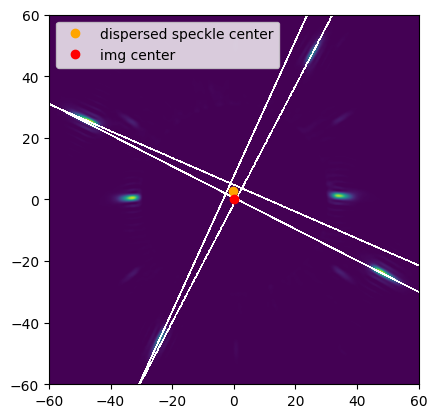

35
least-squares solution: (-0.459067676215415,3.131515880525359)
Estimated dispersion direction 98.33992744213232°
Estimated dispersion magnitude 0.03164985756891859


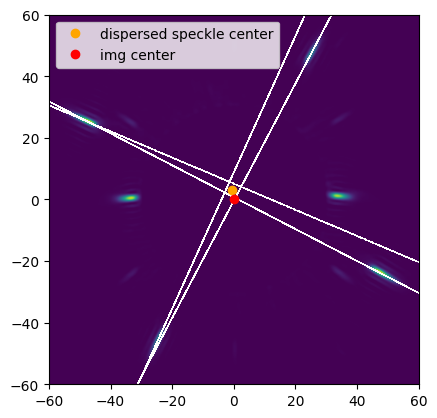

36
least-squares solution: (-0.20448966334693935,3.5693369591869777)
Estimated dispersion direction 93.27892866088368°
Estimated dispersion magnitude 0.03575189834209351


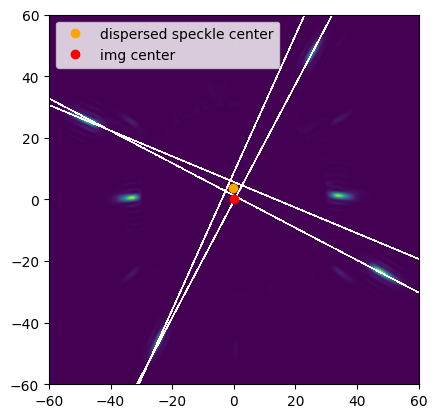

37
least-squares solution: (0.7670555493926122,4.532244867887755)
Estimated dispersion direction 80.39405521093028°
Estimated dispersion magnitude 0.045966963961467905


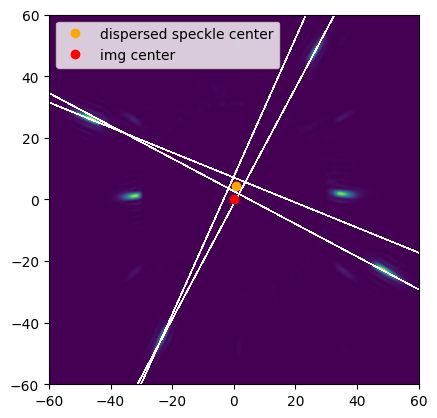

38
least-squares solution: (0.9300202487571433,4.817504006754152)
Estimated dispersion direction 79.07345168523725°
Estimated dispersion magnitude 0.049064531505141895


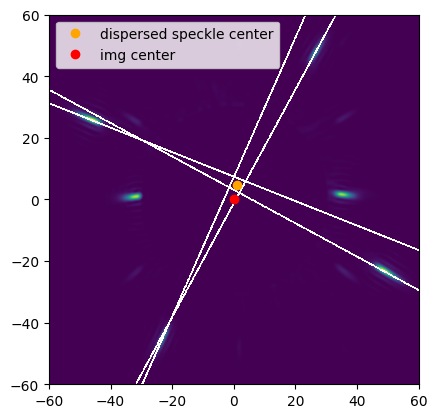

39
least-squares solution: (0.9879488745906073,5.015874032767349)
Estimated dispersion direction 78.85739949423368°
Estimated dispersion magnitude 0.05112243665103868


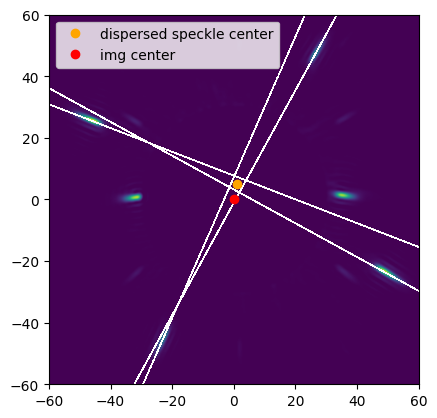

40
least-squares solution: (0.8660134628674293,5.3502493341046335)
Estimated dispersion direction 80.80561259802433°
Estimated dispersion magnitude 0.05419884431881801


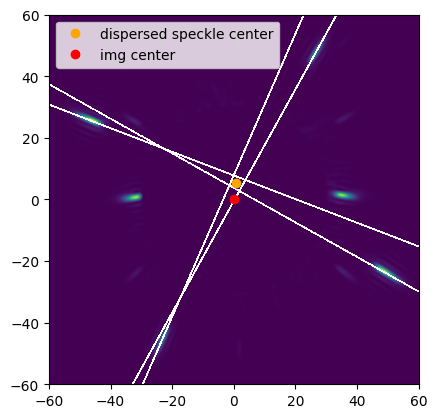

41
least-squares solution: (1.0676423449377144,6.512660211224498)
Estimated dispersion direction 80.6901186829105°
Estimated dispersion magnitude 0.06599591139121486


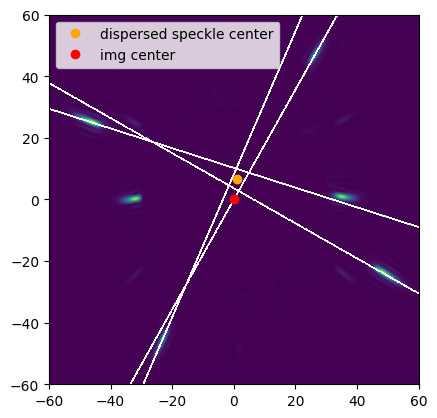

42
least-squares solution: (0.8131223916233761,6.518125565426183)
Estimated dispersion direction 82.88920687089136°
Estimated dispersion magnitude 0.065686474186412


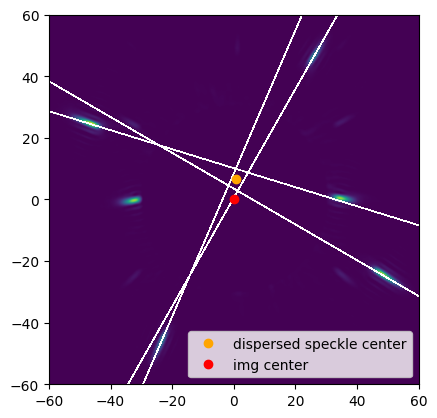

43
least-squares solution: (0.5495211621134297,5.9559584373916525)
Estimated dispersion direction 84.72858044124219°
Estimated dispersion magnitude 0.05981255254170925


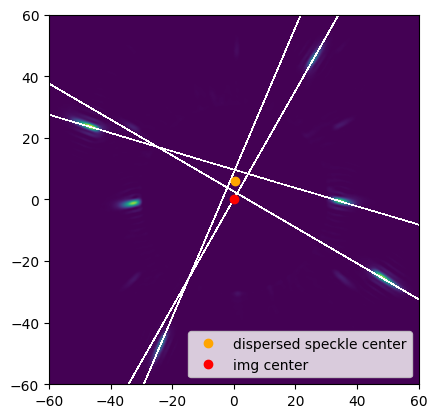

44
least-squares solution: (0.4183316008621539,6.251118722033863)
Estimated dispersion direction 86.17141323889844°
Estimated dispersion magnitude 0.06265100685962051


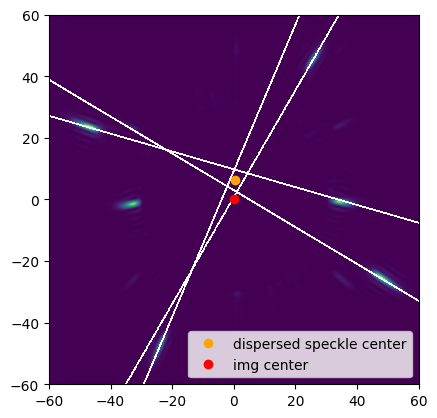

45
least-squares solution: (0.4261123366289982,5.944240890215841)
Estimated dispersion direction 85.89977127318583°
Estimated dispersion magnitude 0.059594942305821096


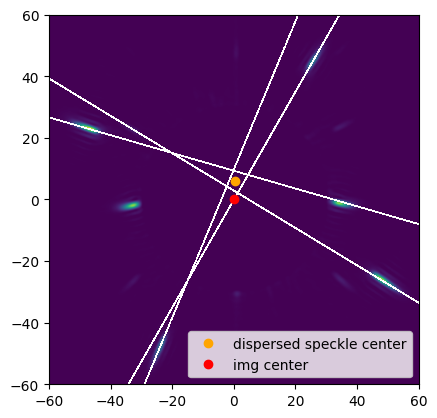

46
least-squares solution: (0.14088240171018615,6.203750596470839)
Estimated dispersion direction 88.6990805427106°
Estimated dispersion magnitude 0.0620535005574415


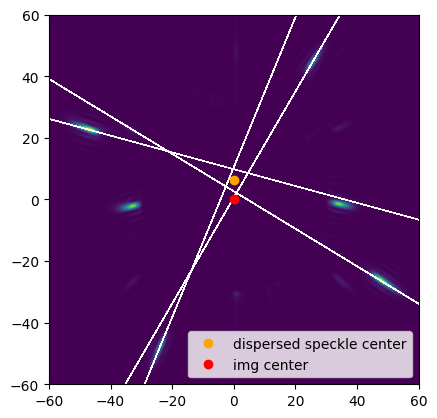

47
least-squares solution: (0.14111722312797087,6.355167008498709)
Estimated dispersion direction 88.72794958831201°
Estimated dispersion magnitude 0.06356733577598937


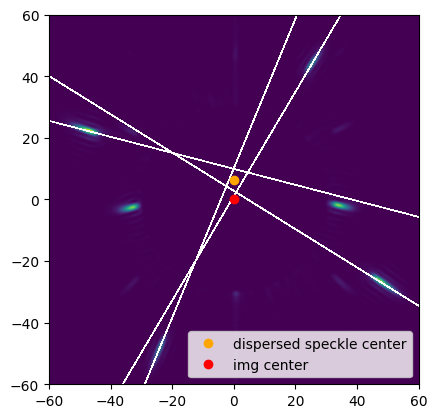

48
least-squares solution: (-0.17536132512278751,6.4135063359411655)
Estimated dispersion direction 91.56621987190034°
Estimated dispersion magnitude 0.0641590329692603


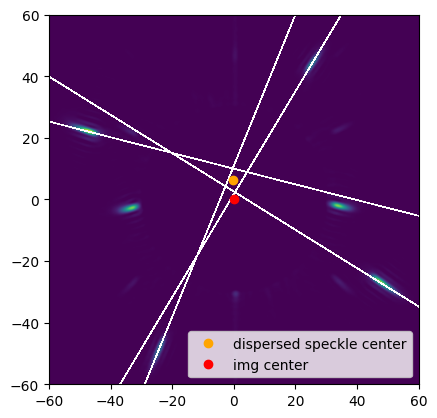

49
least-squares solution: (-0.09618330077000077,6.7520499585541405)
Estimated dispersion direction 90.81612614141237°
Estimated dispersion magnitude 0.0675273499185019


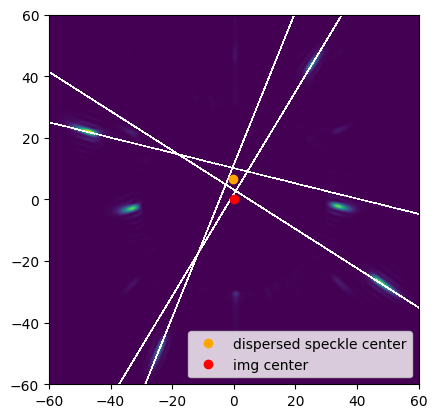

50
least-squares solution: (-0.20553760324184503,6.812910212105173)
Estimated dispersion direction 91.7280231164632°
Estimated dispersion magnitude 0.0681600992256858


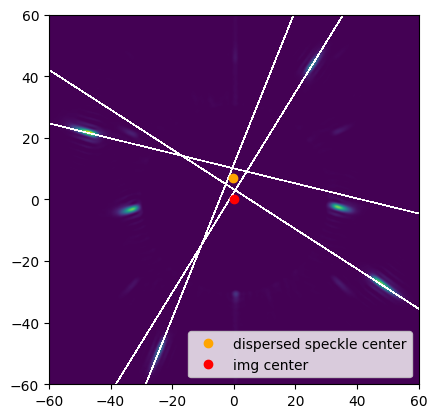

In [75]:
mags =[]
angs = []
misses = []

for i,img in enumerate(cube):
    print(i)
    img = ADC.filter_image(ADC.crop_image(img,extent=510))
    try:
        plt.figure()
        mag,ang = est_mag_dir(img,plotted=True)
        plt.show()
        mags.append(mag)
        angs.append(ang)
    except: 
        misses.append(i)
        pass


[]


(-100.0, 100.0)

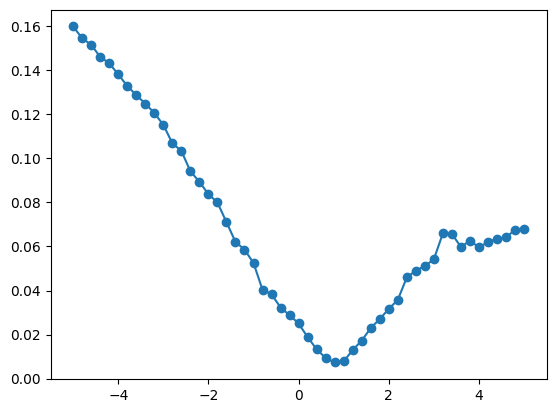

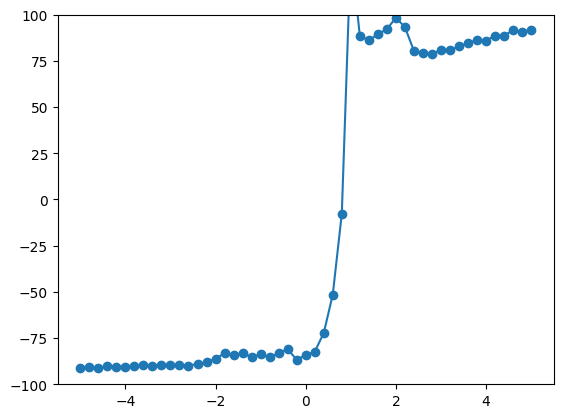

In [76]:
print(misses)
mags = np.array(mags)
angs = np.array(angs)

offsets = np.linspace(-5,5,len(cube))
offsets = np.delete(offsets,misses)

plt.plot(offsets,mags,'o-')
plt.figure()
plt.plot(offsets,angs,'-o')
plt.ylim((-100,100))

least-squares solution: (0.2631536845376258,-15.994177891801257)
Estimated dispersion direction -90.94260769682657°
Estimated dispersion magnitude 0.1599634259123847
least-squares solution: (0.19739204429382085,-15.460064159840213)
Estimated dispersion direction -90.73150514938423°
Estimated dispersion magnitude 0.15461324246180416
least-squares solution: (0.3661960923786995,-15.160758323773768)
Estimated dispersion direction -91.38366506258608°
Estimated dispersion magnitude 0.15165180266978331
least-squares solution: (0.04839171814378727,-14.61441502931203)
Estimated dispersion direction -90.18971892300952°
Estimated dispersion magnitude 0.14614495147194317
least-squares solution: (0.12695670031955777,-14.326314251406794)
Estimated dispersion direction -90.50772952319434°
Estimated dispersion magnitude 0.1432687677178168
least-squares solution: (0.14590886379636933,-13.819648166982937)
Estimated dispersion direction -90.60491058617296°
Estimated dispersion magnitude 0.138204184037868

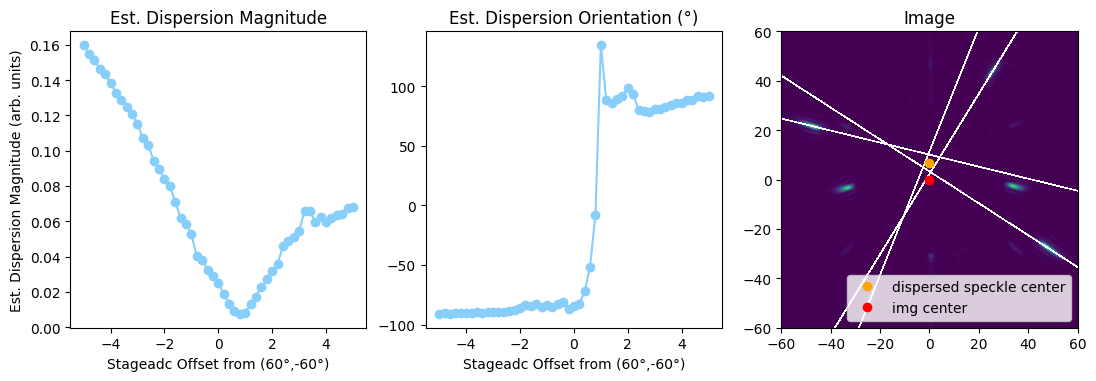

In [86]:
#animation
from matplotlib.animation import PillowWriter

writer = PillowWriter()
fig, axs = plt.subplots(1,3,figsize=(13,5))

for ax in axs:
    ax.set_box_aspect(1)

mags =[]
angs = []
misses = []

with writer.saving(fig,'/Users/Katie/Documents/MagAO-X/figures/ADC/orientations_visualization.gif',100):
    for i,img in enumerate(cube):
        img = ADC.filter_image(ADC.crop_image(img,extent=510))
        try:
            axs[2].clear()
            axs[0].clear()
            axs[1].clear()
            mag,ang = est_mag_dir(img,plotted=True)
            mags.append(mag)
            angs.append(ang)
            axs[0].plot(offsets[0:len(mags)],mags,'o-',color='lightskyblue')
            axs[1].plot(offsets[0:len(angs)],angs,'o-',color='lightskyblue')

            axs[0].set_title('Est. Dispersion Magnitude')
            axs[0].set_xlabel('Stageadc Offset from (60°,-60°)')
            axs[0].set_ylabel('Est. Dispersion Magnitude (arb. units)')
            axs[1].set_title('Dispersion Orientation')
            axs[1].set_title('Est. Dispersion Orientation (°)')
            axs[1].set_xlabel('Stageadc Offset from (60°,-60°)')

            axs[2].set_title('Image')
            writer.grab_frame()
        except: 
            misses.append(i)
            pass

In [87]:
#let's run through an orientations cube and see what happens i guess
orientation_cube = read_field('/Users/Katie/Documents/MagAO-X/Data/ADC/nov5th/corotation_offset.fits')

0
least-squares solution: (0.3822228229578513,2.377882222676343)
Estimated dispersion direction 80.86833951297587°
Estimated dispersion magnitude 0.02408405728134289
1
least-squares solution: (1.197662438155937,3.0884714849357704)
Estimated dispersion direction 68.80446208964234°
Estimated dispersion magnitude 0.033125596491279954
2
least-squares solution: (-0.018940469276590998,2.3750478670341804)
Estimated dispersion direction 90.45691118993258°
Estimated dispersion magnitude 0.02375123388811627
3
least-squares solution: (-0.11717076806284252,2.951877475902514)
Estimated dispersion direction 92.2730848542573°
Estimated dispersion magnitude 0.029542020278967098
4
least-squares solution: (-0.49219870173319796,2.806786601688568)
Estimated dispersion direction 99.94626979487609°
Estimated dispersion magnitude 0.028496158669909014
5
least-squares solution: (-0.7338346339786103,2.5471446180952633)
Estimated dispersion direction 106.07173827506732°
Estimated dispersion magnitude 0.026507468

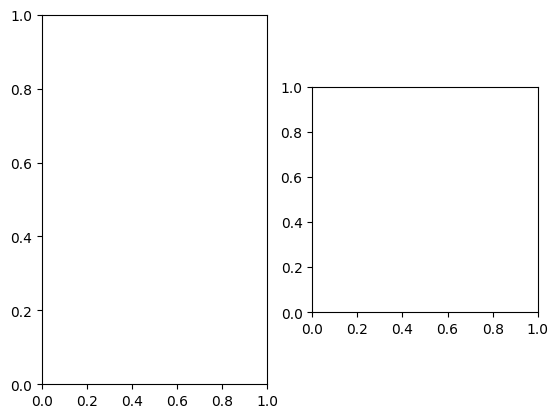

In [117]:
mags =[]
angs = []
misses = []

writer = PillowWriter(fps=4)
fig,ax = plt.subplots(1,2)

with writer.saving(fig,'/Users/Katie/Documents/MagAO-X/figures/ADC/orientations_cube.gif',100):
    for i,img in enumerate(orientation_cube):
        print(i)
        try:
            ax[1].clear()
            ax[0].clear()
            img = ADC.filter_image(ADC.crop_image(img,extent=510))
            mag,ang = est_mag_dir(img,plotted=True)
            mags.append(mag)
            angs.append(ang)
            ax[0].plot(angs,'o-',color='lightskyblue')
            writer.grab_frame()
        except: 
            misses.append(i)
            pass

[14]


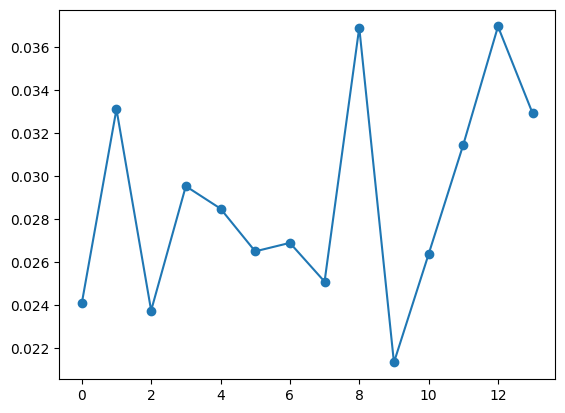

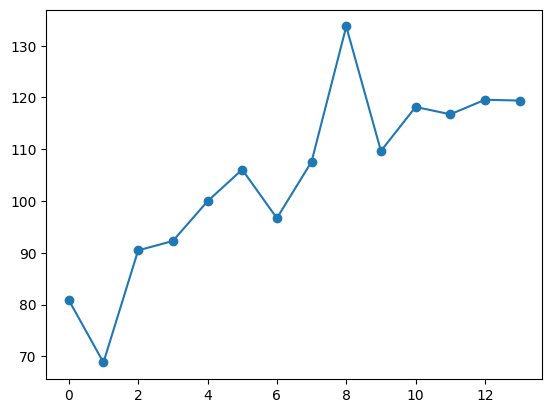

In [114]:
print(misses)
mags = np.array(mags)
angs = np.array(angs)

plt.plot(mags,'o-')
plt.figure()
plt.plot(angs,'-o')